# RM402E – Statistics & Data Analysis
## GROUP PROJECT – Impact of Generative AI on Students
Rennes School of Business

---

**Research question:** *Does the way students use generative AI help or hurt their academic
performance and well-being?*

We analyse a real dataset of **50,000 students** following the full course workflow:
general information → cleaning → distributions & probability → EDA → hypothesis testing →
machine learning.

| # | Team member | Section they own |
|---|-------------|------------------|
| 1 | **Juan Pablo García** | Import, general information & cleaning |
| 2 | **Doaa** | Descriptive statistics, distribution & probability |
| 3 | **Ana** | Exploratory data analysis (charts) |
| 4 | **Zaid** | Hypothesis testing |
| 5 | **Ikram** | Machine learning & conclusions |

**GitHub repository:** https://github.com/Jp-Rsb/SDA_Group1_Team4
**Dataset:** [AI Impact on Students](https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students)
(Kaggle, *laveshjadon*) — 50,000 rows × 16 columns · **CC0** license.

---
# Part 1 — Import, general information & cleaning


# 0. Import libraries and read the file

In [ ]:
# IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm, shapiro

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [ ]:
# READ THE FILE
# On Google Colab, upload the CSV first (Files > Upload), then run this cell.
df = pd.read_csv("ai_student_impact_dataset.csv")
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


# 1. General information on the dataset

In [ ]:
# Number of rows and columns
print(df.shape)
print("**********************")
df.info()

(50000, 16)
**********************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 

In [ ]:
# Descriptive statistics: quantitative (numerical) variables
df.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [ ]:
# Descriptive statistics: qualitative (text) variables
df.describe(include="object")

,Major_Category,Year_of_Study,Primary_Use_Case,Prompt_Engineering_Skill,Institutional_Policy,Burnout_Risk_Level
count,50000,50000,50000,50000,50000,50000
unique,5,5,5,3,3,3
top,STEM,Junior,Debugging/Troubleshooting,Beginner,Allowed_With_Citation,Medium
freq,15059,11045,12295,18495,25224,21144


In [ ]:
# Number of missing values per column
print("Missing values per column:")
df.isna().sum()

Missing values per column:


Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

In [ ]:
# Number of duplicated rows
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


# 2. Clean the dataset
### 2.1 Duplicates

In [ ]:
# Remove duplicates (if any)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (50000, 16)


### 2.2 Missing values
- **Numerical** columns → replace by the **mean**
- **Text (categorical)** columns → replace by the **mode** (most frequent value)

In [ ]:
# Select numerical and categorical columns
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(include="object").columns

# Fill numerical columns with the mean
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())
# Fill categorical columns with the mode
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isna().sum().sum())
print("Shape of the clean dataset:", df.shape)

Remaining missing values: 0
Shape of the clean dataset: (50000, 16)


### 2.3 Create a new column we will use later

In [ ]:
# GPA_Change = how much the GPA moved during the semester
df["GPA_Change"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
df[["Pre_Semester_GPA", "Post_Semester_GPA", "GPA_Change"]].head()

,Pre_Semester_GPA,Post_Semester_GPA,GPA_Change
0,2.418,2.393,-0.025
1,3.821,3.696,-0.125
2,3.398,3.499,0.101
3,3.789,4.000,0.211
4,3.635,3.798,0.163


**Cleaning comment.** The dataset has **50,000 students and 16 columns**. There are **no duplicated
rows and no missing values**, so the mean/mode cleaning step changes nothing here — we still run it
because it is the standard procedure. We add one new column, `GPA_Change`, used in the next parts.

**Handoff to Doaa (Part 2).**

---
# Part 3 — Exploratory data analysis (charts)

# 5. Exploratory data analysis

### 5.1 Correlation heatmap

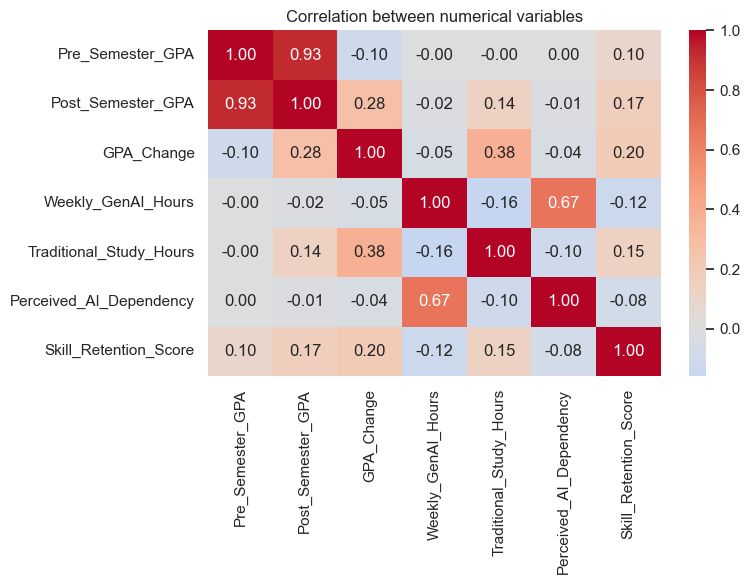

In [ ]:
num = ["Pre_Semester_GPA", "Post_Semester_GPA", "GPA_Change", "Weekly_GenAI_Hours",
       "Traditional_Study_Hours", "Perceived_AI_Dependency", "Skill_Retention_Score"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numerical variables")
plt.tight_layout(); plt.show()

### 5.2 GPA change by prompt-engineering skill

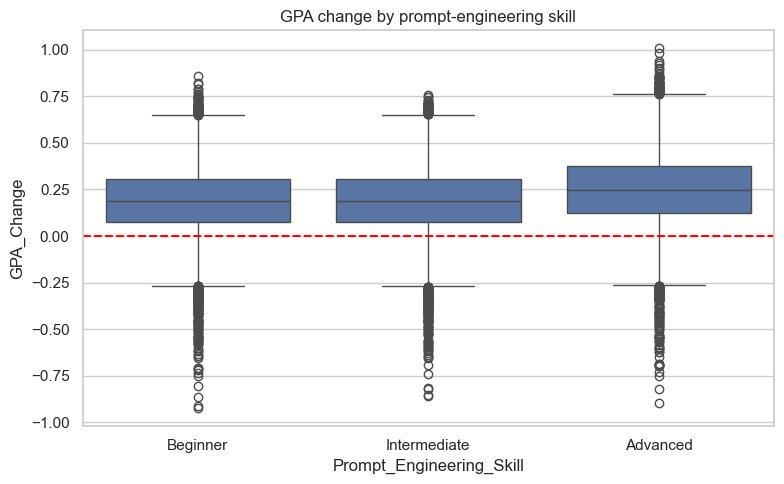

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Prompt_Engineering_Skill", y="GPA_Change",
            order=["Beginner", "Intermediate", "Advanced"])
plt.axhline(0, color="red", linestyle="--")
plt.title("GPA change by prompt-engineering skill")
plt.tight_layout(); plt.show()

### 5.3 Weekly AI hours by burnout level

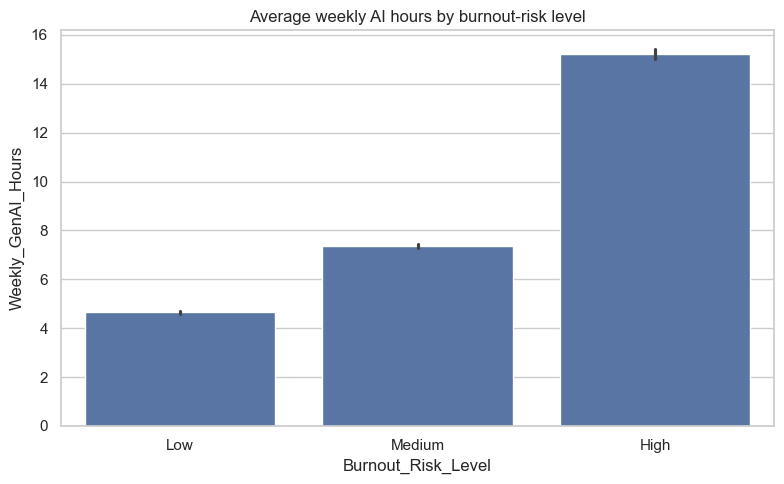

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Burnout_Risk_Level", y="Weekly_GenAI_Hours",
            order=["Low", "Medium", "High"])
plt.title("Average weekly AI hours by burnout-risk level")
plt.tight_layout(); plt.show()

### 5.4 Study hours vs GPA change

/Users/jp/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/jp/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/jp/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


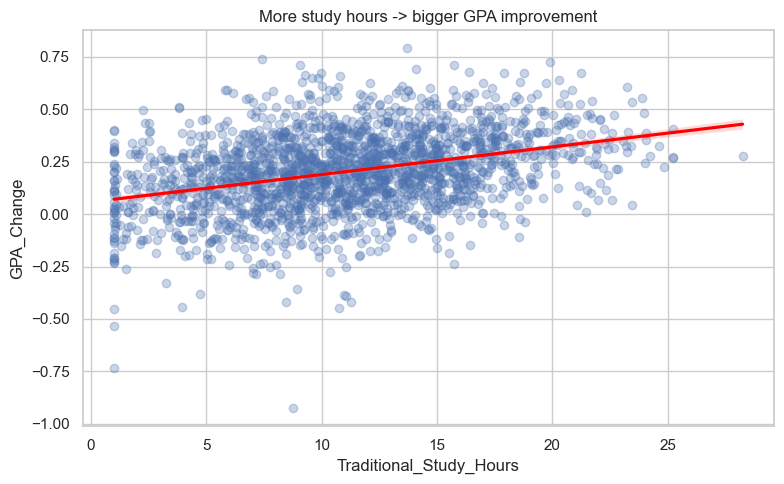

In [ ]:
sample = df.sample(2000, random_state=42)   # sample so the scatter is readable
plt.figure(figsize=(8, 5))
sns.regplot(data=sample, x="Traditional_Study_Hours", y="GPA_Change",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("More study hours -> bigger GPA improvement")
plt.tight_layout(); plt.show()

**Comment.**
- `Weekly_GenAI_Hours` and `Perceived_AI_Dependency` are strongly linked (+0.66).
- `Traditional_Study_Hours` has the strongest positive link with GPA improvement (+0.38).
- Students with **high burnout** use far more AI per week than low-burnout students.
- *Advanced* students seem to improve their GPA a bit more than beginners (tested in Part 4).

**Handoff to Zaid (Part 4).**

---
# Part 4 — Hypothesis testing

For each test we use **α = 0.05**. As in class, we first check normality with Shapiro-Wilk, then
choose the right test (t-test if normal, non-parametric test if not).

In [ ]:
from scipy.stats import levene, ttest_ind, mannwhitneyu, ttest_rel, wilcoxon, f_oneway

### 6.1 Q1 – GPA change: paid vs free subscription (independent samples)
H0: the mean GPA change is the same for paid and free users
H1: it is different · α = 0.05

In [ ]:
# Select the two groups
paid = df[df["Paid_Subscription"] == True]["GPA_Change"]
free = df[df["Paid_Subscription"] == False]["GPA_Change"]
print("Paid mean:", round(paid.mean(), 3), " Free mean:", round(free.mean(), 3))


In [ ]:
# Normality test on a sample of each group
print("Shapiro paid p =", shapiro(paid.sample(500, random_state=1)).pvalue)
print("Shapiro free p =", shapiro(free.sample(500, random_state=1)).pvalue)
# Equal variances?
print("Levene p =", levene(paid, free).pvalue)

In [ ]:
# The groups look normal (Shapiro p > 0.05) but the variances differ (Levene p < 0.05)
# -> the correct test is Welch's t-test (equal_var=False); we also show Mann-Whitney as a check
print("Welch t-test p =", ttest_ind(paid, free, equal_var=False).pvalue)
print("Mann-Whitney p =", mannwhitneyu(paid, free).pvalue)

**Conclusion Q1.** The groups are approximately normal but have unequal variances, so we use
**Welch's t-test** (Mann-Whitney agrees). p < 0.05 → we **reject H0**: there is a statistically
significant difference. **But** the two averages (0.207 vs 0.200) are almost identical. With 50,000
students even a tiny difference becomes significant, so this difference is **not important in
practice**: *statistically significant ≠ meaningful*.

### 6.2 Q2 – Pre-semester vs post-semester GPA (dependent / paired samples)
The two GPAs are measured on the **same students** → paired test.
H0: mean difference = 0 · H1: mean difference ≠ 0 · α = 0.05

In [ ]:
pre = df["Pre_Semester_GPA"]
post = df["Post_Semester_GPA"]
print("Shapiro differences p =", shapiro(df["GPA_Change"].sample(500, random_state=1)).pvalue)

In [ ]:
# Not normal -> Wilcoxon (we also show the paired t-test)
print("Paired t-test p =", ttest_rel(post, pre).pvalue)
print("Wilcoxon      p =", wilcoxon(post, pre).pvalue)
print("Mean GPA change =", round(df["GPA_Change"].mean(), 3))

**Conclusion Q2.** p < 0.05 → we **reject H0**. The post-semester GPA is significantly **higher**
than the pre-semester GPA: on average students improved by about **+0.20 points**.

### 6.3 Q3 – GPA change across prompt-engineering skill (ANOVA, 3 groups)
H0: the three skill groups have the same mean GPA change
H1: at least one group is different · α = 0.05

In [ ]:
beginner     = df[df["Prompt_Engineering_Skill"] == "Beginner"]["GPA_Change"]
intermediate = df[df["Prompt_Engineering_Skill"] == "Intermediate"]["GPA_Change"]
advanced     = df[df["Prompt_Engineering_Skill"] == "Advanced"]["GPA_Change"]

F, p = f_oneway(beginner, intermediate, advanced)
print(df.groupby("Prompt_Engineering_Skill")["GPA_Change"].mean().round(3))
print("\nANOVA F =", round(F, 1), " p =", p)

**Conclusion Q3.** p < 0.05 → we **reject H0**. *Advanced* students improve the most (≈ +0.25)
versus beginners (≈ +0.19). **Using AI well matters more than using it a lot.**

**Handoff to Ikram (Part 5).**